# SpaceX Falcon 9 – Machine Learning Prediction

In [1]:
import pandas as pd, numpy as np, seaborn as sns, matplotlib.pyplot as plt
from sklearn import preprocessing
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix
data = pd.read_csv('https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/dataset_part_2.csv')
X = pd.read_csv('https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/dataset_part_3.csv')
Y = data['Class'].to_numpy()
X = preprocessing.StandardScaler().fit(X).transform(X)
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=2); Y_test.shape

(18,)

In [2]:
def plot_confusion_matrix(y, y_predict, title):
    ax = plt.subplot(); sns.heatmap(confusion_matrix(y, y_predict), annot=True, ax=ax)
    ax.set_xlabel('Predicted labels'); ax.set_ylabel('True labels'); ax.set_title(title)
    ax.xaxis.set_ticklabels(['did not land','land']); ax.yaxis.set_ticklabels(['did not land','landed']); plt.show()

/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  w

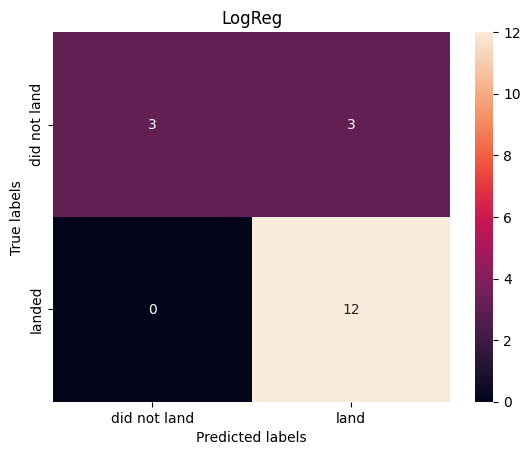

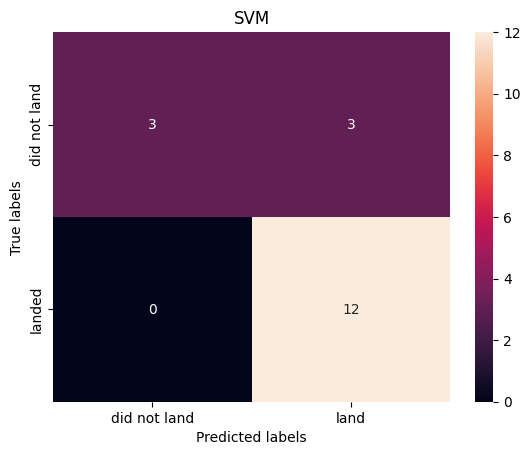

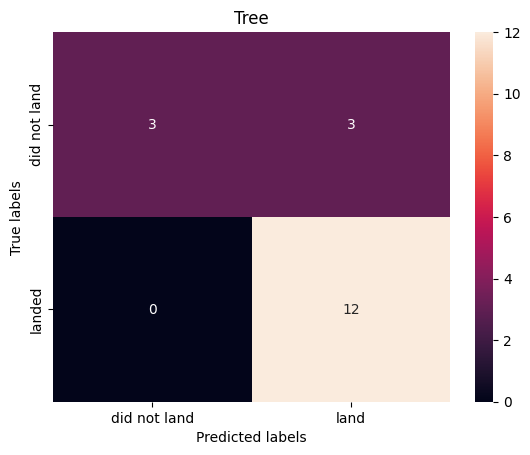

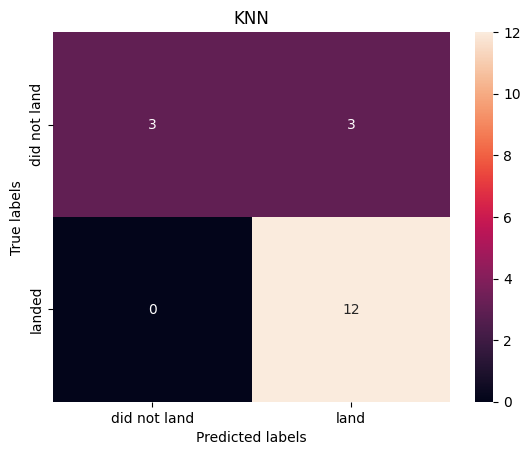

,best_params,cv_accuracy,test_accuracy
LogReg,"{'C': 0.01, 'penalty': 'l2', 'solver': 'lbfgs'}",0.846429,0.833333
SVM,"{'C': 1.0, 'gamma': 0.03162277660168379, 'kern...",0.848214,0.833333
Tree,"{'criterion': 'gini', 'max_depth': 8, 'max_fea...",0.876786,0.833333
KNN,"{'algorithm': 'auto', 'n_neighbors': 10, 'p': 1}",0.848214,0.833333


In [3]:
models = {
 'LogReg': (LogisticRegression(), {'C':[0.01,0.1,1],'penalty':['l2'],'solver':['lbfgs']}),
 'SVM': (SVC(), {'kernel':('linear','rbf','poly','sigmoid'),'C':np.logspace(-3,3,5),'gamma':np.logspace(-3,3,5)}),
 'Tree': (DecisionTreeClassifier(random_state=2), {'criterion':['gini','entropy'],'splitter':['best','random'],'max_depth':[2*n for n in range(1,10)],
          'max_features':['sqrt'],'min_samples_leaf':[1,2,4],'min_samples_split':[2,5,10]}),
 'KNN': (KNeighborsClassifier(), {'n_neighbors':list(range(1,11)),'algorithm':['auto','ball_tree','kd_tree','brute'],'p':[1,2]})}
results = {}
for name, (m, grid) in models.items():
    cv = GridSearchCV(m, grid, cv=10).fit(X_train, Y_train)
    results[name] = {'best_params': cv.best_params_, 'cv_accuracy': cv.best_score_, 'test_accuracy': cv.score(X_test, Y_test)}
    plot_confusion_matrix(Y_test, cv.predict(X_test), name)
pd.DataFrame(results).T

In [4]:
best = max(results, key=lambda k: (results[k]['test_accuracy'], results[k]['cv_accuracy'])); print('Best model:', best)

Best model: Tree
